# Summative Lab: DataVine Analytics

In this lab I build three prototype machine learning solutions: a wine classifier (k-NN + PCA), a feed recommender (PCA + cosine similarity), and a crime pattern analysis (K-Means + GMM)

In [28]:
!pip install rdatasets

In [29]:
#the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, silhouette_score,
                             adjusted_rand_score)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.feature_selection import SelectKBest, f_classif
from rdatasets import data

sns.set_style("whitegrid")

### Loading the 3 datasets & EDA

In [30]:
# Wine
wine_data = load_wine()
wine_df = pd.DataFrame(wine_data.data, columns=wine_data.feature_names)
wine_df["target"] = wine_data.target

# Chickwts (drop the useless row-number column)
chickwts = data("chickwts").drop(columns="rownames")

# USArrests (use the state names as the index)
usarrests = data("USArrests").set_index("rownames")
usarrests.index.name = "State"

print("Wine:", wine_df.shape, "| Chickwts:", chickwts.shape, "| USArrests:", usarrests.shape)

Wine: (178, 14) | Chickwts: (71, 2) | USArrests: (50, 4)


In [31]:
datasets = {"Wine": wine_df, "Chickwts": chickwts, "USArrests": usarrests}

check = pd.DataFrame({
    name: {"rows": df.shape[0],
           "columns": df.shape[1],
           "missing values": int(df.isnull().sum().sum()),
           "duplicate rows": int(df.duplicated().sum())}
    for name, df in datasets.items()
}).T
check

,rows,columns,missing values,duplicate rows
Wine,178,14,0,0
Chickwts,71,2,0,1
USArrests,50,4,0,0


In [32]:
# Consistency checks on the categorical column and value ranges
print("Feed types in Chickwts:")
print(chickwts["feed"].value_counts())
print("\nAny negative values in USArrests?", (usarrests < 0).any().any())
print("Any negative weights in Chickwts?", (chickwts["weight"] < 0).any())

Feed types in Chickwts:
feed
soybean      14
linseed      12
casein       12
sunflower    12
meatmeal     11
horsebean    10
Name: count, dtype: int64

Any negative values in USArrests? False
Any negative weights in Chickwts? False


### Standardization - so that one feature doesnt outweigh another one

In [33]:
# Standardize
wine_scaled = pd.DataFrame(StandardScaler().fit_transform(wine_df.drop(columns="target")),
                           columns=wine_data.feature_names)
chick_scaled = pd.DataFrame(StandardScaler().fit_transform(chickwts[["weight"]]), columns=["weight"])
arrests_scaled_df = pd.DataFrame(StandardScaler().fit_transform(usarrests),
                                 columns=usarrests.columns, index=usarrests.index)

for name, df in [("Wine", wine_scaled), ("Chickwts", chick_scaled), ("USArrests", arrests_scaled_df)]:
    print(name, "-> max |mean|:", round(df.mean().abs().max(), 4),
          "| std range:", df.std().round(2).min(), "to", df.std().round(2).max())

Wine -> max |mean|: 0.0 | std range: 1.0 to 1.0
Chickwts -> max |mean|: 0.0 | std range: 1.01 to 1.01
USArrests -> max |mean|: 0.0 | std range: 1.01 to 1.01


In [34]:
print("WINE"); display(wine_df.describe().T.round(2))
print("CHICKWTS"); display(chickwts.groupby("feed")["weight"].describe().round(1))
print("USARRESTS"); display(usarrests.describe().T.round(2))

WINE


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


CHICKWTS


,count,mean,std,min,25%,50%,75%,max
feed,,,,,,,,
casein,12.0,323.6,64.4,216.0,277.2,342.0,370.8,404.0
horsebean,10.0,160.2,38.6,108.0,137.0,151.5,176.2,227.0
linseed,12.0,218.8,52.2,141.0,178.0,221.0,257.8,309.0
meatmeal,11.0,276.9,64.9,153.0,249.5,263.0,320.0,380.0
soybean,14.0,246.4,54.1,158.0,206.8,248.0,270.0,329.0
sunflower,12.0,328.9,48.8,226.0,312.8,328.0,340.2,423.0


USARRESTS


,count,mean,std,min,25%,50%,75%,max
Murder,50.0,7.79,4.36,0.8,4.08,7.25,11.25,17.4
Assault,50.0,170.76,83.34,45.0,109.00,159.00,249.00,337.0
UrbanPop,50.0,65.54,14.47,32.0,54.50,66.00,77.75,91.0
Rape,50.0,21.23,9.37,7.3,15.08,20.10,26.18,46.0


##  k-NN Classification on the Wine Dataset

I use PCA to reduce the dimensions and GridSearchCV to tune k-NN.

In [35]:
# The wine classes are named categories (class_0, class_1, class_2); I encode them as numbers
wine_df["variety"] = wine_df["target"].map(dict(enumerate(wine_data.target_names)))

le = LabelEncoder()
wine_df["target_encoded"] = le.fit_transform(wine_df["variety"])

print(dict(zip(le.classes_, le.transform(le.classes_))))
wine_df[["variety", "target_encoded"]].drop_duplicates()

{np.str_('class_0'): np.int64(0), np.str_('class_1'): np.int64(1), np.str_('class_2'): np.int64(2)}


,variety,target_encoded
0,class_0,0
59,class_1,1
130,class_2,2


In [36]:
# defining X and y
X = wine_df[wine_data.feature_names]
y = wine_df["target_encoded"]

# stratify keeps the class proportions the same in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit on train only
X_test_scaled = scaler.transform(X_test)

Features reduced from 13 to 10 components
Variance retained: 96.2%


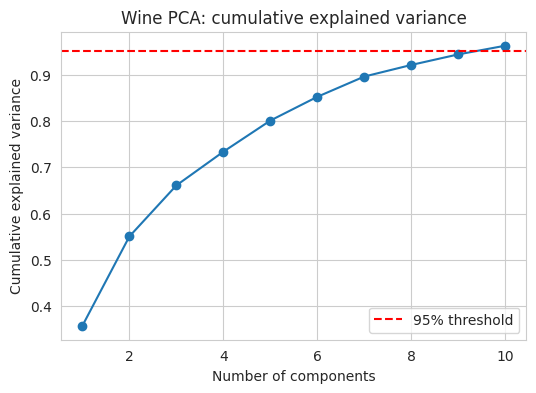

In [37]:
# apply pca , keeps 95% of the variance
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Features reduced from {X_train_scaled.shape[1]} to {pca.n_components_} components")
print(f"Variance retained: {pca.explained_variance_ratio_.sum():.1%}")

plt.figure(figsize=(6, 4))
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1),
         np.cumsum(pca.explained_variance_ratio_), marker="o")
plt.axhline(0.95, color="red", linestyle="--", label="95% threshold")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance")
plt.title("Wine PCA: cumulative explained variance"); plt.legend(); plt.show()

In [38]:
#tune k and the distance metric with GridSearchCV
param_grid = {"n_neighbors": range(1, 31),
              "metric": ["euclidean", "manhattan", "chebyshev"]}

grid_search = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5, scoring="accuracy")
grid_search.fit(X_train_pca, y_train)

best_k = grid_search.best_params_["n_neighbors"]
best_metric = grid_search.best_params_["metric"]
print(f"Best k: {best_k} | Best metric: {best_metric}")
print(f"Best cross-validated accuracy: {grid_search.best_score_:.3f}")

Best k: 18 | Best metric: euclidean
Best cross-validated accuracy: 0.979


In [39]:
#Train the k-NN classifier with the best parameters
knn = KNeighborsClassifier(n_neighbors=best_k, metric=best_metric)
knn.fit(X_train_pca, y_train)
y_pred = knn.predict(X_test_pca)

Test accuracy: 1.000

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



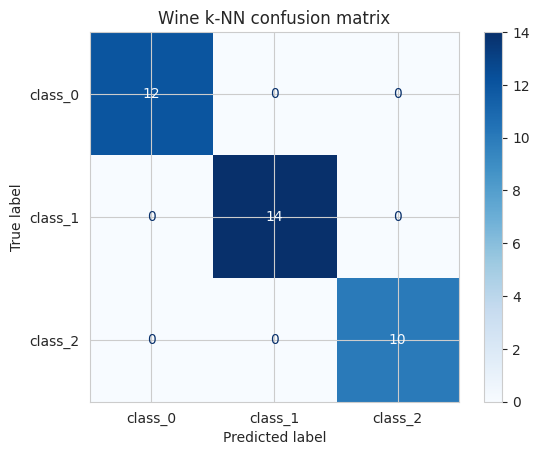

In [40]:
#model evaluation
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=le.classes_).plot(cmap="Blues")
plt.title("Wine k-NN confusion matrix"); plt.show()

**Interpretation:** the model identifies wine varieties from their chemical properties with high accuracy. The classification report shows precision and recall for each variety, and the confusion matrix shows exactly which wines (if any) were mixed up. For the distributor, this means chemical measurements alone can be used for inventory checks and quality control.

## 3. Recommendation System on the Chickwts Dataset

I standardize the weight, reduce it to one principal component, compute cosine similarity between feed types and recommend similar feeds.


In [41]:
#Standardize the weight feature
weight_scaler = StandardScaler()
chickwts["weight_scaled"] = weight_scaler.fit_transform(chickwts[["weight"]])
chickwts[["feed", "weight", "weight_scaled"]].head()

,feed,weight,weight_scaled
0,horsebean,179,-1.061762
1,horsebean,160,-1.306854
2,horsebean,136,-1.616444
3,horsebean,227,-0.442583
4,horsebean,217,-0.571578


In [42]:
#Reduce to one principal component
pca_feed = PCA(n_components=1)
chickwts["pc1"] = pca_feed.fit_transform(chickwts[["weight_scaled"]])
print("Variance explained by PC1:", round(pca_feed.explained_variance_ratio_[0], 3))

Variance explained by PC1: 1.0


### Build one profile per feed type

The dataset has many chicks per feed, so I summarize each feed's PC1 scores into one profile (min, 25%, median, 75%, max). Comparing feed types, not individual chicks, is what makes the recommendation useful.

In [43]:
feed_profile = chickwts.groupby("feed")["pc1"].describe()[["min", "25%", "50%", "75%", "max"]]
feed_profile["mean_weight_g"] = chickwts.groupby("feed")["weight"].mean().round(1)
feed_profile

,min,25%,50%,75%,max,mean_weight_g
feed,,,,,,
casein,-0.584478,0.205621,1.040869,1.411731,1.840642,323.6
horsebean,-1.977632,-1.603544,-1.416500,-1.097236,-0.442583,160.2
linseed,-1.551946,-1.074662,-0.519980,-0.045921,0.615183,218.8
meatmeal,-1.397151,-0.152342,0.021802,0.757078,1.531052,276.9
soybean,-1.332653,-0.703799,-0.171692,0.112099,0.873174,246.4
sunflower,-0.455482,0.663556,0.860274,1.018294,2.085734,328.9


### Compute cosine similarity between feed types

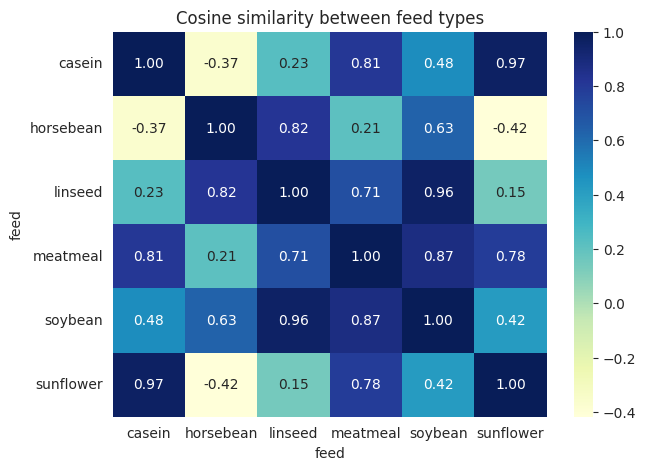

In [44]:
profile_cols = ["min", "25%", "50%", "75%", "max"]
sim_matrix = cosine_similarity(feed_profile[profile_cols])
sim_df = pd.DataFrame(sim_matrix, index=feed_profile.index, columns=feed_profile.index)

plt.figure(figsize=(7, 5))
sns.heatmap(sim_df, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Cosine similarity between feed types"); plt.show()

### Recommend similar feeds

In [45]:
def recommend_feeds(feed_name, n=3):
    if feed_name not in sim_df.index:
        raise ValueError(f"Unknown feed. Choose from: {list(sim_df.index)}")
    scores = sim_df[feed_name].drop(feed_name).sort_values(ascending=False).head(n)
    result = scores.rename("cosine_similarity").to_frame()
    result["mean_weight_g"] = feed_profile.loc[result.index, "mean_weight_g"]
    return result.round(3)

print("Feeds similar to 'soybean':")
display(recommend_feeds("soybean"))
print("Feeds similar to 'casein':")
display(recommend_feeds("casein"))

Feeds similar to 'soybean':


,cosine_similarity,mean_weight_g
feed,,
linseed,0.957,218.8
meatmeal,0.873,276.9
horsebean,0.634,160.2


Feeds similar to 'casein':


,cosine_similarity,mean_weight_g
feed,,
sunflower,0.965,328.9
meatmeal,0.811,276.9
soybean,0.484,246.4


**Interpretation:** each recommendation comes with its similarity score and the average chick weight, so a farmer can check that the suggested feed gives comparable results. One limit I noticed is that cosine similarity compares the *shape* of the weight pattern and not the size.

##  Clustering (K-Means and GMM) on the USArrests Dataset

###  Standardize the dataset

In [46]:
scaler_us = StandardScaler()
us_scaled = scaler_us.fit_transform(usarrests[["Murder", "Assault", "UrbanPop", "Rape"]])
features = ["Murder", "Assault", "UrbanPop", "Rape"]

###  Select the top 3 features

There is no target label in this data, so I first make rough groups with K-Means (3 clusters) and then use SelectKBest (ANOVA F-score) to see which features separate those groups best. (My first attempt used the row index as the target, which is meaningless.)

In [47]:
pseudo_labels = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(us_scaled)

selector = SelectKBest(score_func=f_classif, k=3).fit(us_scaled, pseudo_labels)
feature_scores = pd.Series(selector.scores_, index=features).sort_values(ascending=False)
print(feature_scores.round(1))

selected_features = [f for f, keep in zip(features, selector.get_support()) if keep]
print("\nTop 3 features:", selected_features)
us_selected = us_scaled[:, selector.get_support()]

Assault     74.2
Murder      57.5
Rape        29.0
UrbanPop    14.2
dtype: float64

Top 3 features: ['Murder', 'Assault', 'Rape']


###  Apply PCA (2 components)

In [48]:
pca_us = PCA(n_components=2)
us_pca = pca_us.fit_transform(us_selected)
print("Variance explained by 2 components:", pca_us.explained_variance_ratio_.round(3),
      "| total:", round(pca_us.explained_variance_ratio_.sum(), 3))

Variance explained by 2 components: [0.786 0.153] | total: 0.939


###  optimal number of clusters

For K-Means I use the elbow method. For GMM I use BIC, where lower is better.

Best k for K-Means (elbow): 2
Best k for GMM (lowest BIC): 2


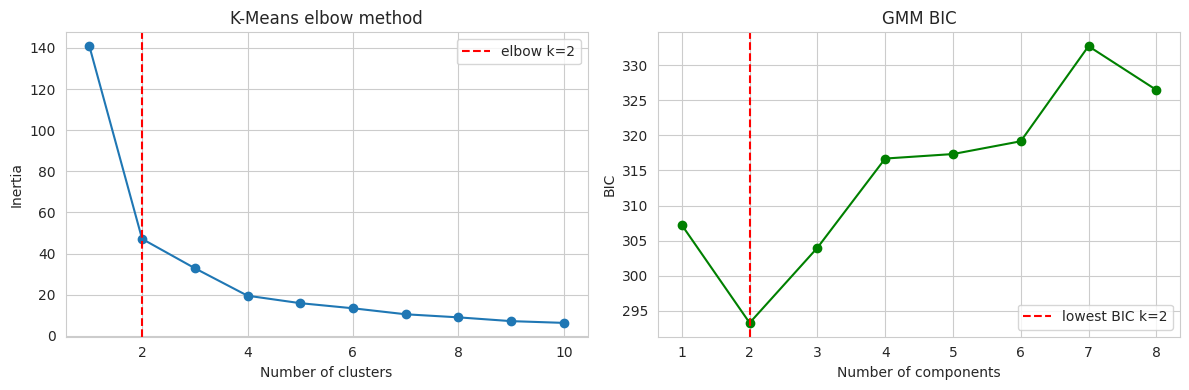

In [49]:
ks = np.arange(1, 11)
inertias = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(us_pca).inertia_ for k in ks]

# Find the elbow: the point furthest from the straight line joining the first and last points
x = (ks - ks.min()) / (ks.max() - ks.min())
y = (np.array(inertias) - min(inertias)) / (max(inertias) - min(inertias))
best_k_kmeans = int(ks[np.argmax(1 - x - y)])

# GMM + BIC (fewer candidates because there are only 50 states)
gmm_ks = np.arange(1, 9)
bics = [GaussianMixture(n_components=k, n_init=5, random_state=42).fit(us_pca).bic(us_pca) for k in gmm_ks]
best_k_gmm = int(gmm_ks[np.argmin(bics)])

print("Best k for K-Means (elbow):", best_k_kmeans)
print("Best k for GMM (lowest BIC):", best_k_gmm)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertias, marker="o")
ax[0].axvline(best_k_kmeans, color="red", linestyle="--", label=f"elbow k={best_k_kmeans}")
ax[0].set_xlabel("Number of clusters"); ax[0].set_ylabel("Inertia"); ax[0].set_title("K-Means elbow method"); ax[0].legend()
ax[1].plot(gmm_ks, bics, marker="o", color="green")
ax[1].axvline(best_k_gmm, color="red", linestyle="--", label=f"lowest BIC k={best_k_gmm}")
ax[1].set_xlabel("Number of components"); ax[1].set_ylabel("BIC"); ax[1].set_title("GMM BIC"); ax[1].legend()
plt.tight_layout(); plt.show()

### Apply K-Means (hard assignments) and GMM (probabilistic)

In [50]:
results = usarrests.copy()

kmeans = KMeans(n_clusters=best_k_kmeans, n_init=10, random_state=42)
results["KMeans_Cluster"] = kmeans.fit_predict(us_pca)

gmm = GaussianMixture(n_components=best_k_gmm, n_init=5, random_state=42)
results["GMM_Cluster"] = gmm.fit_predict(us_pca)

# GMM gives a probability for every cluster; keep the highest one as a confidence score
results["GMM_Confidence"] = gmm.predict_proba(us_pca).max(axis=1)

results.head()

,Murder,Assault,UrbanPop,Rape,KMeans_Cluster,GMM_Cluster,GMM_Confidence
State,,,,,,,
Alabama,13.2,236,58,21.2,1,1,0.995248
Alaska,10.0,263,48,44.5,1,1,0.999967
Arizona,8.1,294,80,31.0,1,1,0.971686
Arkansas,8.8,190,50,19.5,0,0,0.987282
California,9.0,276,91,40.6,1,1,0.999690


### Visualize and compare the clusters

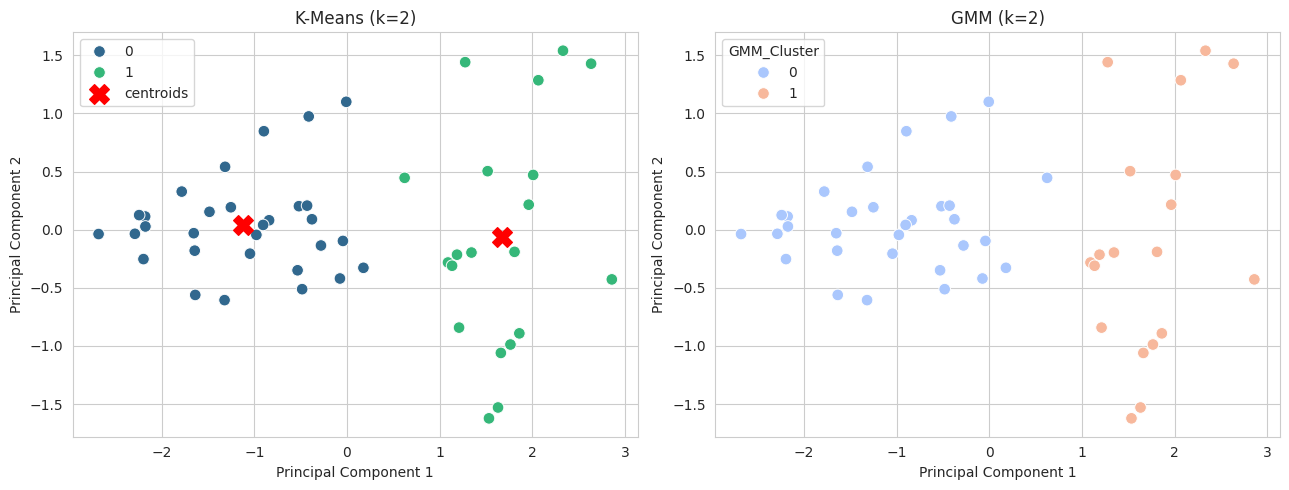

In [51]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=us_pca[:, 0], y=us_pca[:, 1], hue=results["KMeans_Cluster"],
                palette="viridis", s=70, ax=ax[0])
ax[0].scatter(*kmeans.cluster_centers_.T, c="red", marker="X", s=200, label="centroids")
ax[0].set_title(f"K-Means (k={best_k_kmeans})"); ax[0].legend()

sns.scatterplot(x=us_pca[:, 0], y=us_pca[:, 1], hue=results["GMM_Cluster"],
                palette="coolwarm", s=70, ax=ax[1])
ax[1].set_title(f"GMM (k={best_k_gmm})")
for a in ax:
    a.set_xlabel("Principal Component 1"); a.set_ylabel("Principal Component 2")
plt.tight_layout(); plt.show()

In [52]:
# Compare the two models
print("Silhouette score  K-Means:", round(silhouette_score(us_pca, results["KMeans_Cluster"]), 3))
if best_k_gmm > 1:
    print("Silhouette score  GMM    :", round(silhouette_score(us_pca, results["GMM_Cluster"]), 3))
print("Agreement between the two (Adjusted Rand Index):",
      round(adjusted_rand_score(results["KMeans_Cluster"], results["GMM_Cluster"]), 3))

print("\nK-Means vs GMM cluster counts:")
display(pd.crosstab(results["KMeans_Cluster"], results["GMM_Cluster"]))

print("States where GMM is least sure (confidence < 0.8):")
display(results[results["GMM_Confidence"] < 0.8][["KMeans_Cluster", "GMM_Cluster", "GMM_Confidence"]].round(2))

Silhouette score  K-Means: 0.568
Silhouette score  GMM    : 0.561
Agreement between the two (Adjusted Rand Index): 0.92

K-Means vs GMM cluster counts:


GMM_Cluster,0,1
KMeans_Cluster,,
0,30,0
1,1,19


States where GMM is least sure (confidence < 0.8):


,KMeans_Cluster,GMM_Cluster,GMM_Confidence
State,,,


In [53]:
# Describe each K-Means cluster in the original units
cluster_profile = results.groupby("KMeans_Cluster")[["Murder", "Assault", "UrbanPop", "Rape"]].mean().round(1)
cluster_profile["n_states"] = results["KMeans_Cluster"].value_counts().sort_index()
cluster_profile

for c in sorted(results["KMeans_Cluster"].unique()):
    print(f"Cluster {c}:", ", ".join(results[results['KMeans_Cluster'] == c].index[:8]), "...")

Cluster 0: Arkansas, Connecticut, Delaware, Hawaii, Idaho, Indiana, Iowa, Kansas ...
Cluster 1: Alabama, Alaska, Arizona, California, Colorado, Florida, Georgia, Illinois ...


**Interpretation:** the cluster profile table shows what makes each group different (for example high-crime, highly urban states vs low-crime, less urban states). K-Means gives each state exactly one cluster, while GMM also tells me how confident it is, so the states with low confidence sit on the border between two groups. For a policy research firm, those border states are the ones worth a closer look.

## Conclusion

I prepared three datasets, classified wines with a tuned k-NN on PCA features, built a feed recommender with cosine similarity, and found natural crime-pattern groups with K-Means and GMM.